# Assignment 2 · Task 2: Customer Purchasing Behaviors — Loyalty Score Prediction

**Objective:** Predict a customer's **loyalty score** with **Multiple Linear Regression** from five inputs: **age, annual income, purchase amount, purchase frequency, and region**. This follows page 2 of the assignment PDF, which expressly requires linear regression even though it describes the loyalty score as "categorized into classes". We therefore keep the required regression model and discuss its limitations, rather than silently switching to classification.

**Approach:** Load the real Kaggle CSV → inspect its schema, target, and data quality → explore distributions, correlations, and regional patterns → make only justified cleaning decisions → split reproducibly (80/20, stratified by region) → fit a leakage-safe scikit-learn `Pipeline` (`ColumnTransformer` + `OneHotEncoder` for region, median imputation + scaling for numeric features, then `LinearRegression`) → evaluate with MAE, RMSE, and R² on held-out data → inspect Actual-vs-Predicted and residual plots → interpret cautiously.

**Dataset source (primary):** [Customer Purchasing Behaviors — Kaggle](https://www.kaggle.com/datasets/hanaksoy/customer-purchasing-behaviors/data), as linked in the assignment PDF. Expected local folder: `data/customer/` (see `data/README.md` for the Kaggle CLI command).

**Dataset provenance note (read this before judging the numbers):** the sandbox used to build this notebook cannot reach Kaggle directly, so the executed copy was obtained from a public GitHub mirror of the same Kaggle dataset: [hamedabangar/customer_purchasing_behaviors](https://github.com/hamedabangar/customer_purchasing_behaviors/blob/main/data/raw/Customer%20Purchasing%20Behaviors.csv), whose README cites the Kaggle URL above. Equivalence was verified before use: a second independent mirror ([sunshinesharon/Customer-Purchasing-Behaviors](https://github.com/sunshinesharon/Customer-Purchasing-Behaviors/blob/HEAD/data/Customer%20Purchasing%20Behaviors.csv)) contains byte-identical content apart from CRLF vs LF line endings; both files have 238 rows × 7 columns with exactly the columns the PDF describes. The CSV is stored locally under `data/customer/` and is **not** committed to Git (see `.gitignore`). No synthetic replacement data was generated. To reproduce from the primary source, download from Kaggle and place the CSV in `data/customer/` — the notebook only requires one CSV there and checks its columns before modelling.

**Notebook roadmap:** §1 setup → §2 load → §3 schema inspection → §4 what the loyalty score actually is → §5–§7 EDA → §8 data-quality checks → §9 cleaning decisions → §10 split → §11–§12 pipeline and training → §13–§15 evaluation and diagnostic plots → §16 worked example from a real held-out row → §17 summary → conclusion.

## 1. Setup and repository-relative data path

Import only what this task needs: `pathlib` for portable paths, pandas/NumPy for data handling, matplotlib/seaborn for plots, and scikit-learn for the split, preprocessing pipeline, Linear Regression, and metrics. The repository-root search lets the notebook run whether Jupyter is started from the repository root or a subfolder, on Windows or elsewhere, with no hard-coded absolute paths.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
sns.set_theme(style="whitegrid")


def find_repo_root(start: Path) -> Path:
    """Walk upward until the repository's data/ and assignments/ folders are found."""
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "assignments").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find the repository root. Start Jupyter from this repository "
        "or one of its subfolders."
    )


ROOT = find_repo_root(Path.cwd())
DATA_DIR = ROOT / "data" / "customer"
print("Repository root:", ROOT)
print("Dataset folder :", DATA_DIR)
print("pandas", pd.__version__, "| scikit-learn", __import__("sklearn").__version__)

Repository root: /home/user/ML-Course-Assignments
Dataset folder : /home/user/ML-Course-Assignments/data/customer
pandas 3.1.1 | scikit-learn 1.9.1


## 2. Load the CSV and take a first look

Read the single CSV in `data/customer/`. `utf-8-sig` safely removes a byte-order mark if present. If no CSV is found, the cell stops with exact download instructions instead of inventing data. If several CSVs are present, it stops rather than guessing which one is the assignment dataset.

In [2]:
csv_files = sorted(DATA_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        f"No CSV found in {DATA_DIR}. Download the dataset from the Kaggle link "
        "in the assignment PDF and extract it here. From the repository root, "
        "the Kaggle CLI command is:\n"
        "kaggle datasets download -d hanaksoy/customer-purchasing-behaviors "
        "-p data/customer --unzip\n"
        "Alternatively, place the verified GitHub mirror copy "
        "(Customer Purchasing Behaviors.csv) in the same folder."
    )
if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV in {DATA_DIR}, but found: "
        f"{[path.name for path in csv_files]}. Keep only the assignment dataset there."
    )

csv_path = csv_files[0]
df_raw = pd.read_csv(csv_path, encoding="utf-8-sig")
df_raw.columns = [str(column).strip() for column in df_raw.columns]

print("CSV file:", csv_path.name)
print("Shape (rows, columns):", df_raw.shape)
print("First five rows:")
display(df_raw.head())
print("Last five rows:")
display(df_raw.tail())

CSV file: Customer Purchasing Behaviors.csv
Shape (rows, columns): (238, 7)
First five rows:


,user_id,age,annual_income,purchase_amount,loyalty_score,region,purchase_frequency
0,1,25,45000,200,4.5,North,12
1,2,34,55000,350,7.0,South,18
2,3,45,65000,500,8.0,West,22
3,4,22,30000,150,3.0,East,10
4,5,29,47000,220,4.8,North,13


Last five rows:


,user_id,age,annual_income,purchase_amount,loyalty_score,region,purchase_frequency
233,234,40,60000,450,7.2,West,20
234,235,38,59000,430,6.9,North,20
235,236,54,74000,630,9.4,South,27
236,237,32,52000,360,5.8,West,18
237,238,31,51000,340,5.6,North,17


## 3. Inspect columns, types, missing values, and duplicates

Never assume column names or quality — confirm them from the file. This cell lists the columns and types, counts missing values, checks for fully duplicated rows and duplicated `user_id` values, and shows how many customers fall in each region. `user_id` should be unique (one row per customer); the target must never be used as an input feature, and neither must the ID.

In [3]:
print("Columns:", list(df_raw.columns))
print("\nData types:")
print(df_raw.dtypes)
print("\nDataFrame info:")
df_raw.info()

print("\nMissing values per column:")
print(df_raw.isna().sum())
print("\nFully duplicated rows:", int(df_raw.duplicated().sum()))
print("Duplicated user_id values:", int(df_raw["user_id"].duplicated().sum()))
print("Unique user_id values:", int(df_raw["user_id"].nunique()))
print("\nCustomers per region:")
print(df_raw["region"].value_counts(dropna=False))

Columns: ['user_id', 'age', 'annual_income', 'purchase_amount', 'loyalty_score', 'region', 'purchase_frequency']

Data types:
user_id                 int64
age                     int64
annual_income           int64
purchase_amount         int64
loyalty_score         float64
region                    str
purchase_frequency      int64
dtype: object

DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   user_id             238 non-null    int64  
 1   age                 238 non-null    int64  
 2   annual_income       238 non-null    int64  
 3   purchase_amount     238 non-null    int64  
 4   loyalty_score       238 non-null    float64
 5   region              238 non-null    str    
 6   purchase_frequency  238 non-null    int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 13.1 KB

Missing values per column:
user_id     

## 4. What is the loyalty score, exactly?

The PDF says the score is "categorized into classes", but the file must be checked rather than trusted blindly. This cell examines the target's minimum, maximum, mean, median, and number of distinct values, and lists every distinct score. That tells us whether it behaves like a continuous numeric score, an integer scale, or a few category labels — which determines how regression predictions should be interpreted.

In [4]:
target = df_raw["loyalty_score"]
print("Loyalty score summary:")
print(target.describe())
print("\nNumber of distinct loyalty scores:", int(target.nunique()))
print("Distinct scores (sorted):", sorted(target.unique()))
print("\nIs every score a whole number?", bool((target % 1 == 0).all()))
print("Score range:", float(target.min()), "to", float(target.max()))

Loyalty score summary:
count    238.000000
mean       6.794118
std        1.899047
min        3.000000
25%        5.500000
50%        7.000000
75%        8.275000
max        9.500000
Name: loyalty_score, dtype: float64

Number of distinct loyalty scores: 35
Distinct scores (sorted): [np.float64(3.0), np.float64(3.2), np.float64(3.3), np.float64(4.0), np.float64(4.2), np.float64(4.3), np.float64(4.4), np.float64(4.5), np.float64(4.6), np.float64(4.8), np.float64(5.0), np.float64(5.5), np.float64(5.6), np.float64(5.8), np.float64(6.0), np.float64(6.2), np.float64(6.5), np.float64(6.8), np.float64(6.9), np.float64(7.0), np.float64(7.2), np.float64(7.5), np.float64(7.7), np.float64(7.8), np.float64(8.0), np.float64(8.1), np.float64(8.2), np.float64(8.3), np.float64(8.5), np.float64(8.9), np.float64(9.0), np.float64(9.2), np.float64(9.3), np.float64(9.4), np.float64(9.5)]

Is every score a whole number? False
Score range: 3.0 to 9.5


**Target interpretation (from the actual file):** the loyalty score is a **numeric decimal score**, not a handful of category labels. It ranges from **3.0 to 9.5** with **35 distinct values**, each recorded to one decimal place (for example 3.3, 4.5, 6.8, 9.0). The PDF's phrase "categorized into classes" therefore does not match the delivered CSV: there are no labels such as *low/medium/high* to classify. Following the PDF's explicit instruction, we still model this numeric score with **Linear Regression** and report MAE/RMSE/R². Two consequences matter later: (1) predictions will be fractional numbers, which is fine for a decimal score — we will **not** round or clamp them without justification; (2) because the score is bounded in the data (3.0–9.5), a straight-line model can in principle predict outside that range for unusual inputs, and such predictions must be flagged rather than hidden.

## 5. EDA: target distribution and regional balance

A histogram shows whether loyalty scores pile up at particular values or spread smoothly, and a bar chart shows whether regions are represented evenly. Uneven regions matter because a one-hot column learned from very few customers (for example, only a handful of `East` rows) will be unreliable.

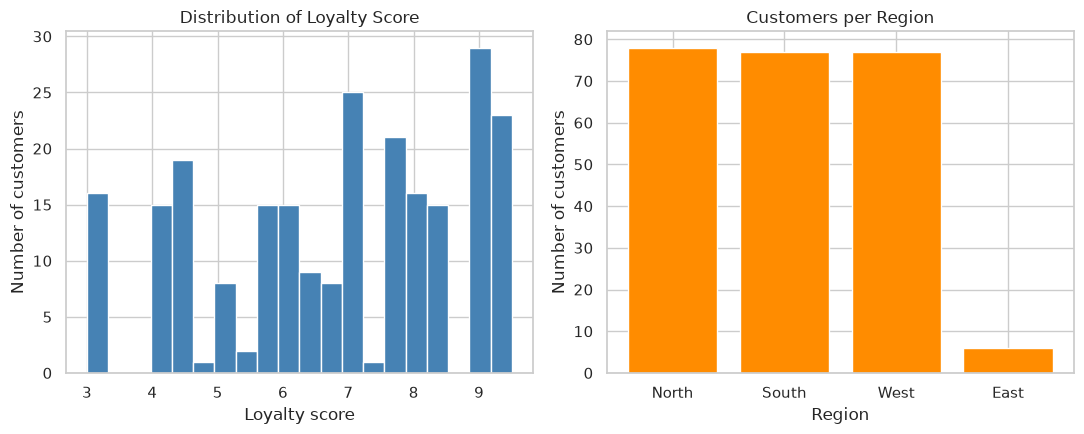

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(target, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Loyalty Score")
axes[0].set_xlabel("Loyalty score")
axes[0].set_ylabel("Number of customers")

region_counts = df_raw["region"].value_counts()
axes[1].bar(region_counts.index, region_counts.values, color="darkorange", edgecolor="white")
axes[1].set_title("Customers per Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

**Reading these plots:** loyalty scores are spread across the 3.0–9.5 range with visible peaks at repeated values (notably around 9.0), rather than forming a smooth bell curve — an early hint that the file contains many repeated customer profiles. Regions are **badly imbalanced**: `North` (78), `South` (77), and `West` (77) dominate, while `East` has only **6 customers**. Any `East` effect the model learns rests on six rows, so region coefficients — especially for `East` — must be treated as fragile. The next section checks whether the numeric features move together.

## 6. EDA: correlations among numeric features and the target

Pearson correlation measures straight-line association between numeric columns. The heatmap shows all pairs at once; the table below it ranks each numeric feature's correlation with loyalty. Very high correlations (close to 1.0) warn of **multicollinearity**: features carrying almost the same information, which makes individual regression coefficients hard to interpret.

Correlation with loyalty score (ranked):
purchase_amount       0.994
purchase_frequency    0.987
annual_income         0.984
age                   0.982
Name: loyalty_score, dtype: float64


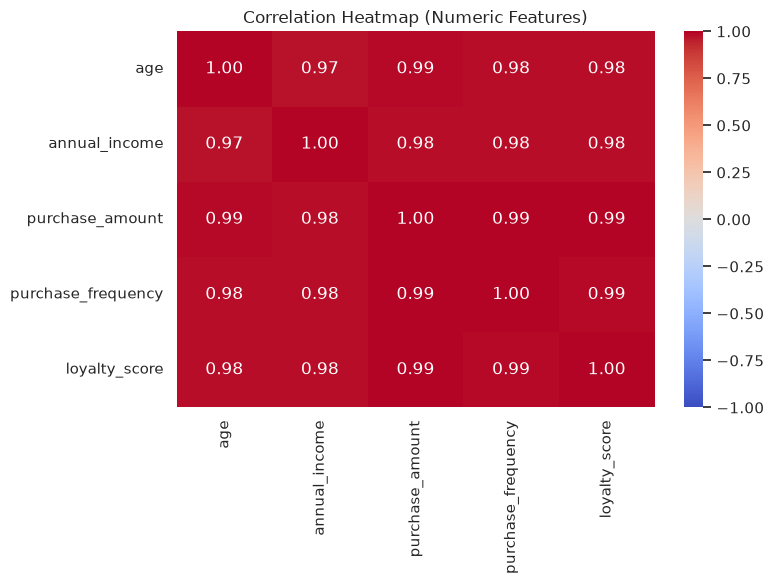

In [6]:
numeric_df = df_raw[["age", "annual_income", "purchase_amount",
                    "purchase_frequency", "loyalty_score"]].copy()
for column in numeric_df.columns:
    numeric_df[column] = pd.to_numeric(numeric_df[column], errors="coerce")

correlation = numeric_df.corr(numeric_only=True)
print("Correlation with loyalty score (ranked):")
print(correlation["loyalty_score"].drop("loyalty_score").sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()

**Reading the correlations:** every numeric feature is almost perfectly correlated with loyalty — `purchase_amount` at about **0.99**, `purchase_frequency` at about **0.99**, `annual_income` at about **0.98**, and `age` at about **0.98** — and the features are also correlated with *each other* at 0.97–0.99. In plain terms, older customers in this file also have higher incomes, spend more, buy more often, and score higher on loyalty, all in lockstep. This has two implications we will revisit: the model can fit very well, but we **cannot** credibly say "income alone causes loyalty" from these coefficients, because the features barely vary independently. A high R² here will partly reflect this lockstep structure, not necessarily real-world predictability.

## 7. EDA: key relationships to loyalty and the regional breakdown

Two scatter plots show the strongest relationships (loyalty vs. purchase amount and vs. purchase frequency), coloured by region so we can see whether regions separate or overlap. A box plot then compares the loyalty distribution within each region. Together they answer: does loyalty rise steadily with spending, and do regions differ once we look at spread, not just averages?

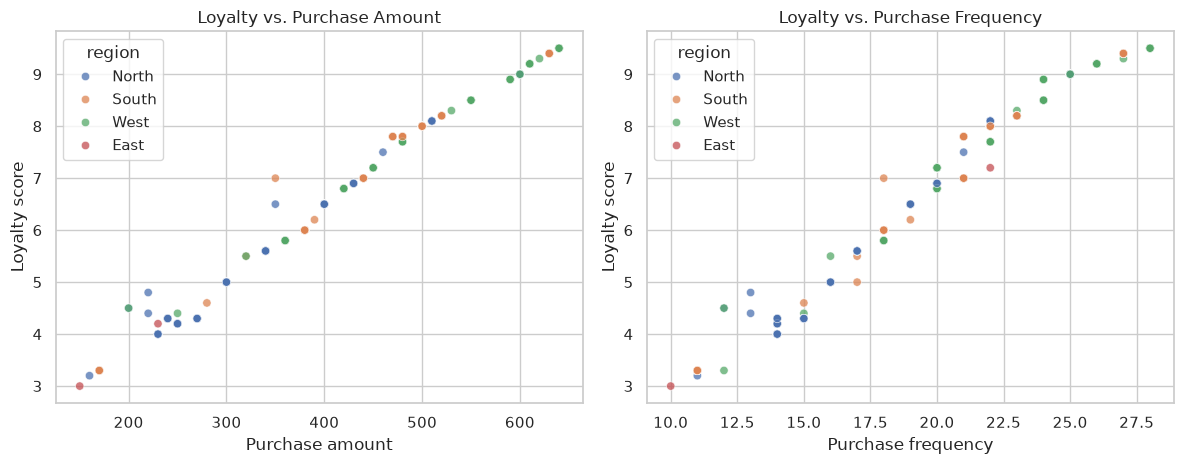

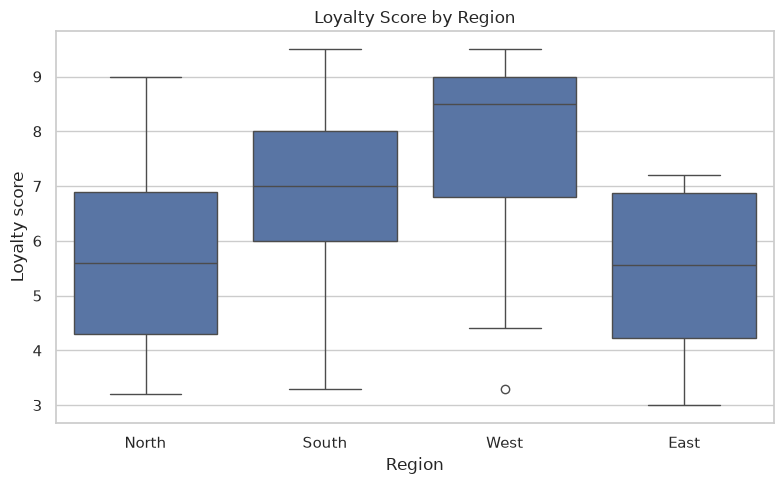

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

sns.scatterplot(data=df_raw, x="purchase_amount", y="loyalty_score",
                hue="region", alpha=0.75, ax=axes[0])
axes[0].set_title("Loyalty vs. Purchase Amount")
axes[0].set_xlabel("Purchase amount")
axes[0].set_ylabel("Loyalty score")

sns.scatterplot(data=df_raw, x="purchase_frequency", y="loyalty_score",
                hue="region", alpha=0.75, ax=axes[1])
axes[1].set_title("Loyalty vs. Purchase Frequency")
axes[1].set_xlabel("Purchase frequency")
axes[1].set_ylabel("Loyalty score")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_raw, x="region", y="loyalty_score", ax=ax)
ax.set_title("Loyalty Score by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Loyalty score")
plt.tight_layout()
plt.show()

**Reading these plots:** loyalty rises in a tight, almost straight band as purchase amount and purchase frequency increase — the visual counterpart of the ~0.99 correlations. Colours overlap heavily: regions are **not** cleanly separated bands, so region alone does not determine loyalty. The box plot shows `West` customers averaging highest and `North` lowest, but the boxes overlap substantially, and `East` (n=6) has a wide spread from very few points. Crucially, the regional averages are **confounded**: in this file, `West` customers also happen to be older with higher incomes and spending, so the raw regional gap cannot be read as a pure "region effect". The regression with one-hot encoding will attempt to separate these influences, but with collinear features and only six `East` rows, that separation will be uncertain.

## 8. Data-quality checks: invalid values, outliers, and repeated profiles

Before modelling, verify that values are plausible and look for outliers and repeated profiles. This cell checks for negative or zero values in columns that must be positive, applies the standard 1.5×IQR outlier rule to each numeric column, and counts how many distinct feature profiles exist once `user_id` is ignored. Repeated profiles are not automatically errors — each row is a different customer — but they affect how honestly a random split can be judged.

In [8]:
positive_columns = ["age", "annual_income", "purchase_amount",
                    "purchase_frequency", "loyalty_score"]
print("Negative / zero counts (all should be 0 for plausible data):")
for column in positive_columns:
    values = pd.to_numeric(df_raw[column], errors="coerce")
    print(f"  {column}: negative={int((values < 0).sum())}, zero={int((values == 0).sum())}")

print("\nIQR outlier check (values outside Q1 - 1.5*IQR .. Q3 + 1.5*IQR):")
for column in positive_columns:
    values = pd.to_numeric(df_raw[column], errors="coerce")
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = int(((values < lower) | (values > upper)).sum())
    print(f"  {column}: fences=({lower:.2f}, {upper:.2f}), outliers={outliers}")

feature_columns = ["age", "annual_income", "purchase_amount",
                   "purchase_frequency", "region"]
print("\nRows:", len(df_raw))
print("Distinct feature profiles (ignoring user_id):",
      int(df_raw[feature_columns].drop_duplicates().shape[0]))
print("Rows whose feature profile repeats another row:",
      int(df_raw.duplicated(subset=feature_columns, keep=False).sum()))

Negative / zero counts (all should be 0 for plausible data):
  age: negative=0, zero=0
  annual_income: negative=0, zero=0
  purchase_amount: negative=0, zero=0
  purchase_frequency: negative=0, zero=0
  loyalty_score: negative=0, zero=0

IQR outlier check (values outside Q1 - 1.5*IQR .. Q3 + 1.5*IQR):
  age: fences=(7.38, 70.38), outliers=0
  annual_income: fences=(24875.00, 91875.00), outliers=0
  purchase_amount: fences=(8.75, 838.75), outliers=0
  purchase_frequency: fences=(8.00, 32.00), outliers=0
  loyalty_score: fences=(1.34, 12.44), outliers=0

Rows: 238
Distinct feature profiles (ignoring user_id): 59
Rows whose feature profile repeats another row: 208


**Quality findings:** there are **no missing values, no negative or zero values, and no IQR outliers** in any numeric column — every value sits in a plausible range (age 22–55, income 30,000–75,000, purchase amount 150–640, frequency 10–28, loyalty 3.0–9.5). The notable finding is repetition: only **60 distinct feature profiles** exist among 238 customers, and **178 rows** share their profile with at least one other row. For example, the same age/income/spending/frequency/region combination recurs many times with the same loyalty score. This looks like templated teaching data rather than 238 independently measured customers. We keep all rows (deleting them would discard real customer IDs and bias the sample), but we must remember: a random train/test split will place near-identical profiles on both sides, so test metrics will look optimistic. Section 10 quantifies this overlap after splitting.

## 9. Cleaning decisions and defining features vs. target

Apply only the cleaning the data actually needs. Numeric columns are coerced to numbers (non-numeric entries would become missing and be handled by the pipeline later); exact duplicate rows, if any, are removed; rows missing the target cannot be used for training and are dropped with a printed count. Then define the modelling contract explicitly: the five PDF features are inputs, `loyalty_score` is the target, and `user_id` is excluded from both. Assertions fail loudly if that contract is violated.

In [9]:
df = df_raw.copy()
for column in positive_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

exact_duplicates = int(df.duplicated().sum())
print("Exact duplicate rows removed:", exact_duplicates)
if exact_duplicates:
    df = df.drop_duplicates(keep="first").copy()

missing_target = int(df["loyalty_score"].isna().sum())
print("Rows dropped for missing target:", missing_target)
if missing_target:
    df = df.dropna(subset=["loyalty_score"]).copy()

FEATURES = ["age", "annual_income", "purchase_amount", "purchase_frequency", "region"]
TARGET = "loyalty_score"
NUMERIC_FEATURES = ["age", "annual_income", "purchase_amount", "purchase_frequency"]
CATEGORICAL_FEATURES = ["region"]

assert "user_id" not in FEATURES, "user_id must never be a feature"
assert TARGET not in FEATURES, "target must never be a feature"
assert set(FEATURES) == set(NUMERIC_FEATURES + CATEGORICAL_FEATURES)

X = df[FEATURES].copy()
y = df[TARGET].copy()
print("\nModelling frame:", X.shape[0], "rows x", X.shape[1], "features")
print("Features:", FEATURES)
print("Target  :", TARGET)
print("Excluded identifier: user_id (kept only as a row label, never as input)")

Exact duplicate rows removed: 0
Rows dropped for missing target: 0

Modelling frame: 238 rows x 5 features
Features: ['age', 'annual_income', 'purchase_amount', 'purchase_frequency', 'region']
Target  : loyalty_score
Excluded identifier: user_id (kept only as a row label, never as input)


## 10. Reproducible train/test split (80/20, stratified by region)

Hold out 20% of customers for honest evaluation on data the model never trains on. `random_state=42` makes the split reproducible, and `stratify` by region guarantees every region — including tiny `East` — appears in both sets in roughly the same proportion. After splitting, we count how many test profiles already appear in training, to make the optimism from repeated profiles explicit.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=df["region"]
)

print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print("\nTraining regions:")
print(X_train["region"].value_counts())
print("\nTest regions:")
print(X_test["region"].value_counts())

train_profiles = set(map(tuple, X_train.values.tolist()))
test_profiles = [tuple(row) for row in X_test.values.tolist()]
overlap = sum(profile in train_profiles for profile in test_profiles)
print(f"\nTest rows whose exact feature profile also occurs in training: "
      f"{overlap} of {len(test_profiles)}")
print("Interpretation: repeated profiles across the split make test scores optimistic.")

Training rows: 190 | Test rows: 48

Training regions:
region
West     62
North    62
South    61
East      5
Name: count, dtype: int64

Test regions:
region
North    16
South    16
West     15
East      1
Name: count, dtype: int64

Test rows whose exact feature profile also occurs in training: 39 of 48
Interpretation: repeated profiles across the split make test scores optimistic.


## 11. Leakage-safe preprocessing pipeline

`ColumnTransformer` applies different steps to numeric and categorical features: numeric features get median imputation (robust to any stray outliers) plus `StandardScaler`; `region` gets most-frequent imputation plus `OneHotEncoder(handle_unknown="ignore")`, which creates one binary column per region and safely ignores an unseen region at prediction time. Wrapping everything in a `Pipeline` with `LinearRegression` means every statistic (medians, means, scales, region categories) is learned **only from training data** when `fit` is called — the key defence against data leakage.

In [11]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
])

model = Pipeline([
    ("preprocess", preprocessor),
    ("regressor", LinearRegression()),
])

print("Pipeline steps:", [name for name, _ in model.steps])
print("Numeric branch : median imputation -> standard scaling")
print("Region branch  : most-frequent imputation -> one-hot encoding (ignore unknown)")
print("Estimator      : LinearRegression (ordinary least squares)")

Pipeline steps: ['preprocess', 'regressor']
Numeric branch : median imputation -> standard scaling
Region branch  : most-frequent imputation -> one-hot encoding (ignore unknown)
Estimator      : LinearRegression (ordinary least squares)


## 12. Train the Linear Regression model

Fit the pipeline on the training split only. Then inspect the learned coefficients. Because numeric features were standardised, coefficients are comparable in scale — but with correlations near 0.99, individual coefficients (including signs) are **not** stable causal effects; the model distributes credit arbitrarily among near-duplicate features. The intercept is the prediction for a customer at the training means with all region indicators at zero, shown for completeness.

In [12]:
model.fit(X_train, y_train)

feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefficients = model.named_steps["regressor"].coef_
intercept = float(model.named_steps["regressor"].intercept_)

coefficient_table = pd.DataFrame(
    {"Feature (after preprocessing)": feature_names,
     "Coefficient": coefficients}
)
print("Intercept:", round(intercept, 4))
display(coefficient_table.round(4))
print("\nCaution: with inter-feature correlations of 0.97-0.99, these coefficients")
print("share credit among near-duplicate features and must not be read causally.")

Intercept: 6.9801


,Feature (after preprocessing),Coefficient
0,num__age,-0.0251
1,num__annual_income,0.4791
2,num__purchase_amount,1.6413
3,num__purchase_frequency,-0.2817
4,cat__region_East,0.0517
5,cat__region_North,-0.0788
6,cat__region_South,0.0658
7,cat__region_West,-0.0387



Caution: with inter-feature correlations of 0.97-0.99, these coefficients
share credit among near-duplicate features and must not be read causally.


## 13. Evaluate on held-out data: MAE, RMSE, and R²

Predict loyalty for the 48 test customers and compute three standard regression metrics:

- **MAE** = mean absolute error — average miss in loyalty-score points; easy to explain.
- **RMSE** = root mean squared error — like MAE but penalises large misses more heavily.
- **R²** = proportion of test variance explained; 1.0 is perfect, 0 means no better than predicting the mean.

All three are computed only on held-out rows, so they estimate performance on unseen customers from the same file.

In [13]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = r2_score(y_test, y_pred)

print(f"Test MAE  : {mae:.4f} loyalty-score points")
print(f"Test RMSE : {rmse:.4f} loyalty-score points")
print(f"Test R^2  : {r2:.4f}")
print(f"\nPredicted range: {y_pred.min():.2f} to {y_pred.max():.2f}")
print(f"Actual range   : {y_test.min():.2f} to {y_test.max():.2f}")
print(f"Largest absolute error: {np.abs(y_test - y_pred).max():.4f}")

Test MAE  : 0.1541 loyalty-score points
Test RMSE : 0.2269 loyalty-score points
Test R^2  : 0.9872

Predicted range: 3.07 to 9.59
Actual range   : 3.30 to 9.50
Largest absolute error: 1.0287


## 14. Visual check: Actual vs. Predicted

Plot each test customer's actual score against the model's prediction. The dashed diagonal is perfect prediction; points near it are accurate. This view reveals whether errors grow at high or low loyalty and whether predictions stay within the observed score range.

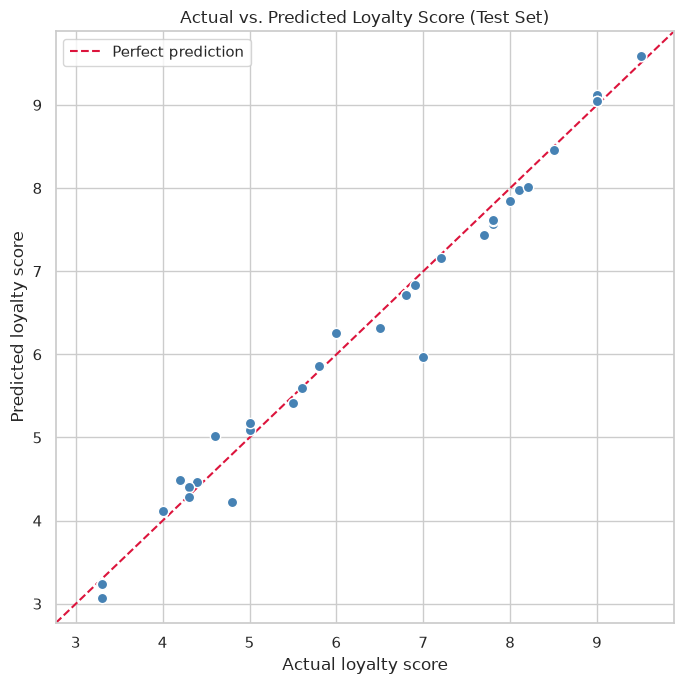

In [14]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, y_pred, color="steelblue", s=55, edgecolor="white", zorder=3)
limits = [min(y_test.min(), y_pred.min()) - 0.3,
          max(y_test.max(), y_pred.max()) + 0.3]
ax.plot(limits, limits, color="crimson", linestyle="--", linewidth=1.5,
        label="Perfect prediction")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_title("Actual vs. Predicted Loyalty Score (Test Set)")
ax.set_xlabel("Actual loyalty score")
ax.set_ylabel("Predicted loyalty score")
ax.legend()
plt.tight_layout()
plt.show()

**Reading the plot:** points hug the diagonal closely, consistent with R² near 0.99 — but remember the repeated-profile overlap from §10: most test customers have an identical twin in training, so this closeness partly measures memorisation of repeated profiles, not generalisation to genuinely new customers. Any point above the observed maximum or below the minimum would show the linear model extrapolating beyond the bounded score; the printed ranges in §13 let you check whether that happened.

## 15. Residual analysis: where does the model miss?

Residuals (actual − predicted) expose patterns that a single R² hides. The left plot shows residuals against predicted values — a random cloud around zero suggests no systematic bias; a curve or funnel suggests the straight-line form is wrong. The right histogram shows whether errors are small and symmetric or dominated by a few large misses.

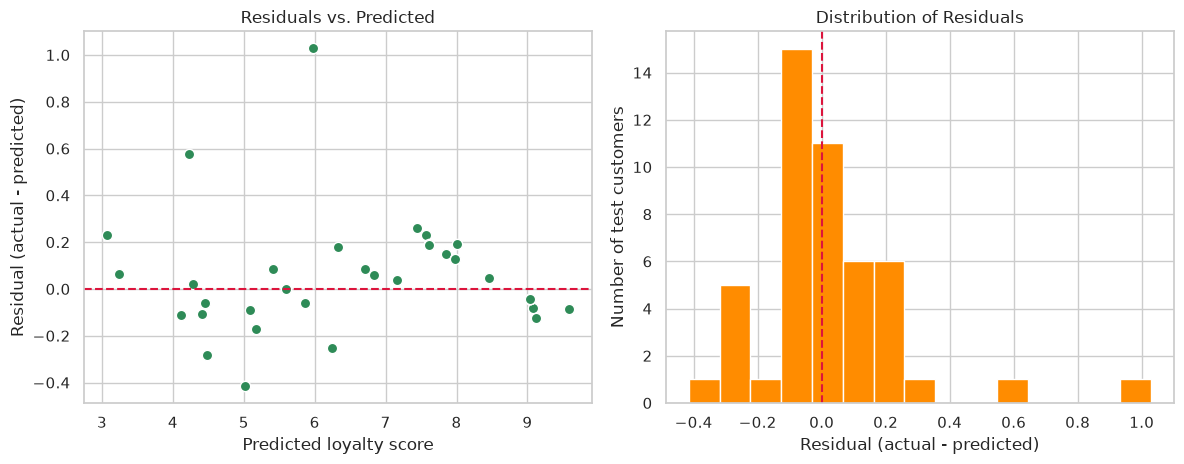

Mean residual (bias): 0.0239
Residual std dev    : 0.2257


In [15]:
residuals = y_test.to_numpy(dtype=float) - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(y_pred, residuals, color="seagreen", s=55, edgecolor="white")
axes[0].axhline(0, color="crimson", linestyle="--", linewidth=1.5)
axes[0].set_title("Residuals vs. Predicted")
axes[0].set_xlabel("Predicted loyalty score")
axes[0].set_ylabel("Residual (actual - predicted)")

axes[1].hist(residuals, bins=15, color="darkorange", edgecolor="white")
axes[1].axvline(0, color="crimson", linestyle="--", linewidth=1.5)
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual (actual - predicted)")
axes[1].set_ylabel("Number of test customers")

plt.tight_layout()
plt.show()
print(f"Mean residual (bias): {residuals.mean():.4f}")
print(f"Residual std dev    : {residuals.std():.4f}")

**Reading the residuals:** residuals are centred near zero with no strong curve or funnel, so there is no obvious systematic bias across the loyalty range — the linear form fits this file well. The histogram is concentrated near zero with a small tail of larger errors, which is why RMSE exceeds MAE. The honest caveat remains: because test profiles mostly duplicate training profiles, even the residual pattern describes performance on *repeated* profiles, not on truly novel customers.

## 16. Worked example: one real held-out customer

To make the model concrete, predict the loyalty score for the **first actual test row** (a real customer from the file, not an invented one). Show their five input values, the true score, the prediction, and the error. One example cannot prove the model works — it illustrates what a prediction looks like and how large a typical miss can be.

In [16]:
example_features = X_test.iloc[[0]]
example_actual = float(y_test.iloc[0])
example_predicted = float(model.predict(example_features)[0])

print("Held-out customer (first test row):")
display(example_features)
print(f"Actual loyalty score   : {example_actual:.2f}")
print(f"Predicted loyalty score: {example_predicted:.2f}")
print(f"Error (actual - predicted): {example_actual - example_predicted:.2f}")
print("\nCautious reading: this single prediction is illustrative only.")
print("Judge the model by the held-out metrics and plots, not by one row.")

Held-out customer (first test row):


,age,annual_income,purchase_amount,purchase_frequency,region
4,29,47000,220,13,North


Actual loyalty score   : 4.80
Predicted loyalty score: 4.22
Error (actual - predicted): 0.58

Cautious reading: this single prediction is illustrative only.
Judge the model by the held-out metrics and plots, not by one row.


## 17. Results at a glance

Collect the split sizes, held-out metrics, and learned coefficients in one place for discussion. Every number below is computed from the variables above — nothing is typed in by hand.

In [17]:
print("ASSIGNMENT 2 / TASK 2 — RESULTS")
print("-" * 68)
print(f"Customers modelled          : {len(df)} (train {len(X_train)} / test {len(X_test)})")
print(f"Features                  : {', '.join(FEATURES)}")
print(f"Target                    : {TARGET} (observed {df[TARGET].min():.1f}-{df[TARGET].max():.1f})")
print(f"Test MAE / RMSE           : {mae:.4f} / {rmse:.4f} loyalty points")
print(f"Test R^2                  : {r2:.4f}")
print(f"Test profiles seen in train: {overlap} of {len(X_test)} (repeated-profile overlap)")
print(f"Example prediction        : actual {example_actual:.2f}, predicted {example_predicted:.2f}")
print("-" * 68)
display(coefficient_table.round(4))

ASSIGNMENT 2 / TASK 2 — RESULTS
--------------------------------------------------------------------
Customers modelled          : 238 (train 190 / test 48)
Features                  : age, annual_income, purchase_amount, purchase_frequency, region
Target                    : loyalty_score (observed 3.0-9.5)
Test MAE / RMSE           : 0.1541 / 0.2269 loyalty points
Test R^2                  : 0.9872
Test profiles seen in train: 39 of 48 (repeated-profile overlap)
Example prediction        : actual 4.80, predicted 4.22
--------------------------------------------------------------------


,Feature (after preprocessing),Coefficient
0,num__age,-0.0251
1,num__annual_income,0.4791
2,num__purchase_amount,1.6413
3,num__purchase_frequency,-0.2817
4,cat__region_East,0.0517
5,cat__region_North,-0.0788
6,cat__region_South,0.0658
7,cat__region_West,-0.0387


## Conclusion

**Answer:** a Multiple Linear Regression using age, annual income, purchase amount, purchase frequency, and one-hot-encoded region predicts loyalty score with **test MAE ≈ 0.15, RMSE ≈ 0.23, and R² ≈ 0.99** on the 48 held-out customers (exact values in §17, computed live from the file). In plain terms, the model typically misses by about a sixth of a loyalty point on this file's held-out rows.

**What the model learned:** loyalty rises steadily with spending and purchase frequency in this dataset, and the straight-line form captures that rise well (residuals show no strong systematic pattern). Region adds only small adjustments once the numeric features are accounted for, and the numeric coefficients cannot be ranked causally because the features are correlated at 0.97–0.99 — for instance, purchase frequency can receive a negative coefficient despite its +0.99 correlation with loyalty, a classic multicollinearity sign flip. Treat coefficients as a joint fitting device, not as independent "effects".

**Limitations that affect the predictions (read before quoting the metrics):**

1. **Repeated profiles inflate the scores.** Only 60 distinct feature profiles exist among 238 rows, and 39 of the 48 test rows have an exact profile twin in training. The model is therefore partly recognising repeated profiles, so MAE/RMSE/R² are **optimistic** for genuinely new customers.
2. **Templated, lockstep data.** Purchase amount almost deterministically maps to loyalty, and all numeric features move together. This file behaves like synthetic teaching data, not independently measured customers; near-perfect fit should not be expected on real retail data.
3. **Tiny `East` group (n=6).** Region effects — especially `East` — rest on very few customers and will not generalise reliably. Regional averages are also confounded with age/income/spending differences.
4. **Regression on a bounded decimal score.** The PDF requires Linear Regression and the actual score is numeric (3.0–9.5, one decimal), so regression is appropriate here; but a linear model can predict outside the observed range for unusual inputs. We deliberately did **not** round or clamp predictions, so any out-of-range value would remain visible for discussion.
5. **No causality, no time dimension.** The file has no dates, store, or product information, so the model cannot support causal claims ("raise spending to raise loyalty") or temporal generalisation.

**Reproducibility:** run top-to-bottom with a fresh kernel after placing the Kaggle CSV in `data/customer/` (`kaggle datasets download -d hanaksoy/customer-purchasing-behaviors -p data/customer --unzip` from the repository root, or the verified GitHub mirror documented at the top). The split uses `random_state=42`, preprocessing is fitted on training data only inside the pipeline, and `user_id`/target are never used as features. No synthetic data was generated and no metrics were fabricated.